In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 2 — Challenge A: network intrusion classification (cyber)

**Team:** Team 1  
**Milestone:** P2 — baselines, nearest neighbours and the evaluation protocol  
**Roles:** R1 Diana Luque; R2 Francisco Moya; R3 Claudia Martínez; R4 Fernando Caceres; R5 Marina García. See `../plantillas/roles.md` for the five-phase rotation.

Primary metric: **macro F1**, on the canonical `cyber_folds.csv` assignment.

Source sections are taken from the team notebooks in this directory. The `p2_source` cell metadata identifies the source notebook and original zero-based cell index. Paths have been adjusted for execution from `notebooks/`; mixed R4 cells have been restricted to this challenge. No model grid, seed or scoring definition has been changed.


# P2.1 — Data contract and exploration (R1)

In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Data paths, relative to the notebook location
DATA_DIR = "../datos"
CYBER_DIR = DATA_DIR + "/cyber"
STORAGE_DIR = DATA_DIR + "/storage"

# Identifier, group and fold columns: never used as model inputs
FORBIDDEN = ["row_id", "feature_group", "config_group", "fold_id"]

# Challenge A — cyber

## 1. Load the contract tables

In [3]:
# --- Challenge A: load development table, groups and class codes ---
# Main table: one row per network connection, with its features and class
cyber = pd.read_csv(CYBER_DIR + "/cyber_development.csv")
# Groups file: tells which group each row belongs to (for validation)
cyber_groups = pd.read_csv(CYBER_DIR + "/cyber_groups.csv")
# Class codes: dictionary that maps each code to its name
with open("../datos/cyber/cyber_class_codes.json") as fh:
    CLASS_NAMES = {int(k): v for k, v in json.load(fh).items()}

# shape = (rows, columns). Both files should have the same number of rows
print("cyber:", cyber.shape, "| groups:", cyber_groups.shape)
print("class codes:", CLASS_NAMES)

cyber.head()

cyber: (34928, 13) | groups: (34928, 2)
class codes: {0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


,row_id,proto,service,conn_state,duration,src_bytes,dst_bytes,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,attack_code
0,C00000,udp,dns,SF,0.001593,37,53,0,1,65,1,81,2
1,C00001,tcp,-,SH,4.036948,0,0,0,3,156,0,0,9
2,C00002,tcp,http,S3,5.165641,1867,1058,0,6,2187,4,1274,9
3,C00003,tcp,http,SF,0.013618,167,2987,0,5,435,7,3359,6
4,C00004,udp,dns,SF,0.017344,58,58,0,1,86,1,86,1


## 2. Verify the schema against the handout

Expected: `row_id`, 11 model features (3 nominal + 8 numeric), `attack_code`. Check the columns, their types, missing values, and that `row_id` matches `cyber_groups.csv`.

In [4]:
CYBER_NOMINAL = ["proto", "service", "conn_state"]
CYBER_NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
                 "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]

# Model input columns: the 11 predictors
CYBER_FEATURES = CYBER_NOMINAL + CYBER_NUMERIC

# --- Challenge A: integrity checks ---
# Goal: make sure the data is clean before using it

# 1. Schema against the handout: row_id + 11 predictors + integer target 
expected_columns = ["row_id"] + CYBER_FEATURES + ["attack_code"]
print("columns as in the handout:", list(cyber.columns) == expected_columns)
print("number of predictors:", len(CYBER_FEATURES), "(expected 11)")

# No identifier, group or fold column may be used as a predictor 
for col in FORBIDDEN:
    print(col, "used as predictor:", col in CYBER_FEATURES, "(expected False)")

# 2. Target: integer type and the same codes as the JSON
print("\ntarget type:", cyber["attack_code"].dtype)
codes_in_data = sorted(cyber["attack_code"].unique().tolist())
codes_in_json = sorted(CLASS_NAMES.keys())
print("codes in data:", codes_in_data)
print("codes in JSON:", codes_in_json)

# Data type of each column
print()
print(cyber.dtypes)

# 3. Both files must list the rows in the same order, because later we attach each row to its group by position
print("\nrow_id aligned with groups file:", cyber["row_id"].equals(cyber_groups["row_id"]))

# 4. Every row must have a unique identifier
print("duplicated row_id:", cyber["row_id"].duplicated().sum(), "(expected 0)")

# 5. Missing values: first sum counts per column, second sum adds all columns
print("missing values:", cyber.isna().sum().sum(), "(expected 0)")

# 6. Range of each numeric predictor. The minimum must be >= 0 so that log1p is defined
print()
for col in CYBER_NUMERIC:
    values = cyber[col]
    positive_values = values[values>0]
    print(col, "| min:", values.min(), "| min non-zero:", positive_values.min(), "| max:", values.max())

# 7. Categories in the text columns and how often each one appears
for col in CYBER_NOMINAL:
    print()
    print(cyber[col].value_counts())

columns as in the handout: True
number of predictors: 11 (expected 11)
row_id used as predictor: False (expected False)
feature_group used as predictor: False (expected False)
config_group used as predictor: False (expected False)
fold_id used as predictor: False (expected False)

target type: int64
codes in data: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
codes in JSON: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

row_id              str
proto               str
service             str
conn_state          str
duration        float64
src_bytes         int64
dst_bytes         int64
missed_bytes      int64
src_pkts          int64
src_ip_bytes      int64
dst_pkts          int64
dst_ip_bytes      int64
attack_code       int64
dtype: object

row_id aligned with groups file: True
duplicated row_id: 0 (expected 0)
missing values: 0 (expected 0)

duration | min: 0.0 | min non-zero: 1e-06 | max: 93372.05713
src_bytes | min: 0 | min non-zero: 1 | max: 1430385581
dst_bytes | min: 0 | min non-zero: 1 | max: 1253826969
miss

_Interpretation:_ 

**Schema:** 34,928 rows x 13 columns, in the handout order: `row_id` (identifier only, never a predictor), 3 nominal predictors read as text (`proto`, `service`, `conn_state`), 8 numeric predictors (`duration` as float, the 7 counts as integers) and the integer target `attack_code`. Its 10 codes are exactly the ones in the JSON. No identifier, group or fold column is in the predictor list

**Integrity:** groups file aligned row by row; no duplicated `row_id`, no missing values; all numeric predictors >= 0, so `log1p` is defined

**Scales:** the byte counts go from a smallest non-zero value of 1 up to about 1.9x10⁹, and `duration` goes from 10⁻⁶ to 9.3x10⁴. On the raw scale a Euclidean distance would be dominated by the byte counts

**Rare categories:** `service=gssapi` has a single row, `dce_rpc` 7 and `smb;gssapi` 15; `conn_state = RSTOS0` has 32 and `proto = icmp` 74. A category with one row is necessarily absent from the training portion of the fold where it is validated, so the encoder must be fitted inside each fold with `handle_unknown="ignore"`

## 3. Class supports

Report the support of each class with its semantic name; name **ransomware's** support explicitly.

In [5]:
# --- Challenge A: class distribution ---
# 1. Number of rows per class, ordered by code
counts = cyber["attack_code"].value_counts().sort_index()

print("code | name | rows | % of total")
for code in counts.index:
    n_rows = counts[code]
    pct = 100 * n_rows /len(cyber)
    print(code, "|", CLASS_NAMES[code], "|", n_rows, "|", round(pct, 2))

# 2. Ransomware: find its code by name
for code, name in CLASS_NAMES. items():
    if name == "ransomware":
        RANSOMWARE = code

n_ransomware = counts[RANSOMWARE]
rows_per_fold = n_ransomware / 5
one_row_in_recall = 100 / rows_per_fold

print("\nransomware rows:", n_ransomware)
print("ransomware rows per fold:", round(rows_per_fold))
print("one row = recall points:", round(one_row_in_recall, 1))

code | name | rows | % of total
0 | backdoor | 1573 | 4.5
1 | ddos | 4800 | 13.74
2 | dos | 4800 | 13.74
3 | injection | 4800 | 13.74
4 | mitm | 805 | 2.3
5 | normal | 4800 | 13.74
6 | password | 4800 | 13.74
7 | ransomware | 208 | 0.6
8 | scanning | 3542 | 10.14
9 | xss | 4800 | 13.74

ransomware rows: 208
ransomware rows per fold: 42
one row = recall points: 2.4


_Interpretation:_ 

**Imbalance:** six classes (`ddos`, `dos`, `injection`, `normal`, `password`, `xss`) have 4,800 rows each (13.74%), while `scanning` has 3,542, `backdoor` 1,573, `mitm` 805 and ransomware only 208 (0.60%). With 5 folds that is about 42 ransomware rows per fold, so one row changes its fold recall by ~2.4 points. Accuracy alone is not enough: report per-class recall with its spread across folds. The six classes with 4,800 rows are the ones capped at 6,000 by the course. As PROVENANCE requires, every per-class figure for ransomware must be reported beside its support (208)

## 4. Feature groups

Number of distinct `feature_group` values, and how many groups contain more than one row (exact feature-vector duplicates).

In [6]:
# --- Challenge A: rows sharing a feature_group ---
# Are rows that share a group exact copies? Do they have the same class?

# 1. Copy of the data with the group column added
# Adding it by position is safe because section 3 confirmed the row order matches. The original `cyber` table never gets the group column
cyber_with_group = cyber.copy()
cyber_with_group["feature_group"] = cyber_groups["feature_group"].values

# 2. How many rows each group has
rows_per_group = cyber_with_group["feature_group"].value_counts()
print("number of groups:", len(rows_per_group))
print("max rows per group:", rows_per_group.max())

# 3. Keep only the rows of groups with 2 or more rows
multi_row_groups = rows_per_group[rows_per_group > 1].index
dup = cyber_with_group[cyber_with_group["feature_group"].isin(multi_row_groups)]
print("groups with more than one row:", len(multi_row_groups))
print("rows in those groups:", len(dup))

# 4. Go through those groups one by one
n_identical = 0
n_mixed_labels = 0
n_all_labels_differ = 0
unavoidable_errors = 0
conflicting_groups = []

for group_id, rows in dup.groupby("feature_group"):
    # Exact copies: only one distinct feature vector inside the group
    n_distinct_vectors = len(rows[CYBER_FEATURES].drop_duplicates())
    if n_distinct_vectors == 1:
        n_identical += 1

    # Labels inside the group
    n_labels = rows["attack_code"].nunique()
    if n_labels > 1:
        n_mixed_labels += 1
        conflicting_groups.append(group_id)
    if n_labels == len(rows):
        n_all_labels_differ += 1

    # For identical rows, the best a model can do is predict the most frequent class, so the remaining rows of the group are errors whatever the model
    most_frequent_count = rows["attack_code"].value_counts().max()
    unavoidable_errors += len(rows) - most_frequent_count

print("groups with identical features:", n_identical)
print("groups with more than one class:", n_mixed_labels)
print("groups where every copy has a different label:", n_all_labels_differ)

# 5. Reverse check: identical feature vectors never sit in different groups. If so, the number of distinct feature vectors equals the number of groups
n_distinct_vectors_total = len(cyber[CYBER_FEATURES].drop_duplicates())
print("distinct feature vectors:", n_distinct_vectors_total, "| groups:", len(rows_per_group))

# 6. Show the conflicting rows with their class name
conflict_rows = dup[dup["feature_group"].isin(conflicting_groups)]
conflict_rows = conflict_rows[["feature_group", "attack_code"]].copy()
conflict_rows["name"] = conflict_rows["attack_code"].map(CLASS_NAMES)
print(conflict_rows.sort_values("feature_group"))

# 7. Maximim accuracy any model can reach
max_accuracy = 100 * (len(cyber) - unavoidable_errors) / len(cyber)
print("unavoidable errors (minimum):", unavoidable_errors)
print("maximum accuracy (%):", round(max_accuracy, 2))

number of groups: 34883
max rows per group: 4
groups with more than one row: 38
rows in those groups: 83
groups with identical features: 38
groups with more than one class: 38
groups where every copy has a different label: 38
distinct feature vectors: 34883 | groups: 34883
       feature_group  attack_code        name
712              900            7  ransomware
11515            900            1        ddos
23261            900            4        mitm
1162            1461            5      normal
12949           1461            7  ransomware
...              ...          ...         ...
29524          30307            7  ransomware
33322          33667            8    scanning
26958          33667            2         dos
28257          35301            3   injection
31209          35301            1        ddos

[83 rows x 3 columns]
unavoidable errors (minimum): 45
maximum accuracy (%): 99.87


_Interpretation:_ 

**Feature groups:** 38 of the 34,883 groups have more than one row (83 rows, at most 4 per group). Rows in the same group are exact copies, and identical feature vectors never sit in different groups, so each `feature_group` is exactly one distinct feature vector. Grouped validation keeps every copy on the same side

**Label conflicts:** all 38 groups mix classes, ransomware included; in fact every copy inside a group carries a different label. At least 45 errors are unavoidable: maximum accuracy (34,928 - 45) / 34,928 = 99.87%. The rows are kept: the modelling table is fixed

**Why every copy has a different label:** the course removed exact duplicates of `(X,y)` before distributing the data. Two rows with the same features and the same class were kept once, so the only copies left are those whose labels differ. This also explains the 45: with every label different, the best a model can do is one correct row per group, so 
83-38=45 error

## 5. Preprocessing block (cyber)

One-hot on the 3 nominal predictors; `log1p` then standardisation on the 8 numeric predictors. It is returned unfitted, to be placed inside a `Pipeline` so that it is fitted inside each fold. **Publish this cell for R2 and R4.**

In [7]:
def make_cyber_preprocessor():
    numeric_steps = Pipeline([
        ("log1p", FunctionTransformer(np.log1p)),
        ("scake", StandardScaler())
    ])

    nominal_steps = OneHotEncoder(handle_unknown="ignore")

    preprocessor = ColumnTransformer([
        ("nominal", nominal_steps, CYBER_NOMINAL),
        ("numeric", numeric_steps, CYBER_NUMERIC),
    ])
    return preprocessor

_Why `log1p` and why scaling:_ 

**`log1p`:** the numeric predictors are counts and durations spanning up to nine orders of magnitude, with many zeros. `log` is undefined at 0, while `log1p(x) = log(1 + x)` maps 0 to 0 and is defined because every value is >= 0. It compresses the range: 1.4x10⁹ bytes becomes about 21, so a few huge connections no longer dominate

**Scaling:** after `log1p` the columns still have different ranges (`duration` stays below about 11.4, the byte counts reach about 21). `StandardScaler` puts every numeric column on mean 0 and standard deviation 1, so no predictor dominates a distance just because of its units

**Inside each fold:** the block is returned unfitted. Inside a `Pipeline`, the means, standard deviations and one-hot categories are learned only from the training portion of each fold, so no information from the validation rows leaks into de model

### Data provenance

| Field | Value |
|---|---|
| Dataset | **TON_IoT Network dataset** |
| Authority | **UNSW Canberra at ADFA**, Cyber Range and IoT Labs |
| Principal investigator | **Dr Nour Moustafa** |
| Project page | <https://research.unsw.edu.au/projects/toniot-datasets> |
| Terms | Free use for **academic research in perpetuity**; commercial use requires the authors' permission; **users must cite all eight papers referenced by the project page** |
| Subset used | `Train_Test_Network` (`train_test_network.csv`) |

See [the course provenance record](../datos/cyber/PROVENANCE.md) for derivation, exclusions and terms. The course-provided modelling table is preserved unchanged.

# P2.2 — Grouped evaluation protocol (R4)

## 0. Setup

In [8]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (GroupKFold, KFold, StratifiedGroupKFold,
                                     StratifiedKFold, cross_validate)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

## 1. Data

`row_id`, `feature_group` and `config_group` are loaded but are **never** estimator inputs.

In [9]:
cyber = pd.read_csv("../datos/cyber/cyber_development.csv")

cyber_groups = pd.read_csv("../datos/cyber/cyber_groups.csv")

CYBER_NOMINAL = ["proto", "service", "conn_state"]

CYBER_NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
                 "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]

X_cyber = cyber[CYBER_NOMINAL + CYBER_NUMERIC]

y_cyber = cyber["attack_code"]

g_cyber = cyber_groups["feature_group"]

## 2. Course-fixed comparison pipelines

Fixed by the statement for P2.2 (KNN with `n_neighbors=5`).

In [10]:
cyber_pipeline = Pipeline([
    ("prep", ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore"), CYBER_NOMINAL),
        ("numeric", Pipeline([("log1p", FunctionTransformer(np.log1p)),
                               ("scale", StandardScaler())]), CYBER_NUMERIC),
    ])),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

## 3. P2.2 (a) — Build the grouped protocols

- Cyber: `StratifiedGroupKFold(n_splits=5)`, groups = `feature_group`.

Pass `PROJECT_RANDOM_STATE` only where randomness is actually used (e.g. `shuffle=True`).

In [11]:
assert (cyber["row_id"] == cyber_groups["row_id"]).all()

cv_cyber = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=PROJECT_RANDOM_STATE)

folds_cyber = list(cv_cyber.split(X_cyber, y_cyber, groups=g_cyber))

for name, folds in [("cyber", folds_cyber)]:
    print(name, [(len(tr), len(va)) for tr, va in folds])

cyber [(27942, 6986), (27942, 6986), (27943, 6985), (27942, 6986), (27943, 6985)]


## P2.2 (b) - Verify and report the invariants

For every fold, print the number of shared feature groups, the number of validation classes, and ransomware support.

In [12]:
n_classes = y_cyber.nunique()

print("Cyber: StratifiedGroupKFold on feature_group")
for k, (tr, va) in enumerate(folds_cyber, start=1):
    shared = set(g_cyber.iloc[tr]) & set(g_cyber.iloc[va])
    classes_val = y_cyber.iloc[va].nunique()
    print(f"  fold {k}: shared feature_group = {len(shared)} | "
          f"classes in validation = {classes_val}/{n_classes} | "
          f"ransomware (7) in validation = {(y_cyber.iloc[va] == 7).sum()}")
    assert not shared



Cyber: StratifiedGroupKFold on feature_group
  fold 1: shared feature_group = 0 | classes in validation = 10/10 | ransomware (7) in validation = 42
  fold 2: shared feature_group = 0 | classes in validation = 10/10 | ransomware (7) in validation = 42
  fold 3: shared feature_group = 0 | classes in validation = 10/10 | ransomware (7) in validation = 41
  fold 4: shared feature_group = 0 | classes in validation = 10/10 | ransomware (7) in validation = 41
  fold 5: shared feature_group = 0 | classes in validation = 10/10 | ransomware (7) in validation = 42


_Interpretation:_

All invariants hold in the five cyber folds. In Challenge A no `feature_group` is shared between a fold's training and validation portions, and all ten classes appear in every validation portion, including `ransomware` (class 7), which has only 41–42 validation rows per fold out of 208.

**How this differs from ordinary row-wise cross-validation.** A row-wise `KFold` or `StratifiedKFold` assigns each *row* to a fold independently, so rows that belong to the same group can fall on both sides of the split. The grouped protocols assign whole *groups* to folds instead, so the validation portion contains only groups the model has never seen in training. In Challenge A, identical feature vectors are kept on the same side of the split. The grouping constraint is the price of this guarantee: `StratifiedGroupKFold` can only balance the classes as far as the groups allow, which is why we check explicitly that every class (especially `ransomware`) reaches every validation portion.

## 6. P2.2 (d) — Cyber: grouped vs ungrouped

Same `cyber_pipeline`, metric macro F1; `StratifiedGroupKFold` vs `StratifiedKFold`. Report the difference **as measured**, whatever its size and sign.

In [13]:
protocols_cyber = {
    "grouped StratifiedGroupKFold": folds_cyber,
    "ungrouped StratifiedKFold": StratifiedKFold(n_splits=5, shuffle=True,
                                                 random_state=PROJECT_RANDOM_STATE),
}

rows = []
for name, cv in protocols_cyber.items():
    res = cross_validate(cyber_pipeline, X_cyber, y_cyber, cv=cv, scoring="f1_macro")
    f1 = res["test_score"]
    rows.append({"protocol": name, **{f"fold {i+1}": s for i, s in enumerate(f1)},
                 "mean macro F1": f1.mean(), "spread (max-min)": f1.max() - f1.min()})

cyber_comparison = pd.DataFrame(rows).set_index("protocol")
display(cyber_comparison.round(4))

diff = (cyber_comparison.loc["grouped StratifiedGroupKFold", "mean macro F1"]
        - cyber_comparison.loc["ungrouped StratifiedKFold", "mean macro F1"])
print(f"grouped - ungrouped = {diff:+.4f} in macro F1")

,fold 1,fold 2,fold 3,fold 4,fold 5,mean macro F1,spread (max-min)
protocol,,,,,,,
grouped StratifiedGroupKFold,0.9419,0.9466,0.9516,0.9399,0.9408,0.9442,0.0117
ungrouped StratifiedKFold,0.9372,0.9404,0.9476,0.9536,0.9424,0.9443,0.0164


grouped - ungrouped = -0.0001 in macro F1


_Interpretation:_

With the same pipeline (KNN, $K_{NN}=5$) and the same metric, only the splitting protocol changes. The mean macro F1 is 0.9442 under `StratifiedGroupKFold` and 0.9443 under `StratifiedKFold`: the measured difference (grouped minus ungrouped) is $-0.0001$, i.e. negligible. It is far smaller than the fold-to-fold spread (about 0.012 for the grouped protocol and 0.016 for the ungrouped one). On this challenge, with this pipeline, the observed difference between protocol means is small. The fold numbers under the two protocols do not identify the same validation rows, so they are not paired model comparisons.

This is not surprising once the group structure is looked at: the development table has 34,883 distinct `feature_group` values for 34,928 rows, so almost every group is a single row and only 45 rows are repeats of another row's feature vector (0.13% of the data). There is very little duplication that an ungrouped split could place on both sides of a fold, so there is very little leakage to remove. 

The absence of a measurable gap here does not make the ungrouped estimate preferable; the argument for grouping is given in the next section.

## 7. P2.2 (e) — Why splitting identical feature groups is undesirable

Argue in terms of **what the validation score is meant to estimate**, not the size of the gap.

_Argument:_

The argument does not depend on the size or the sign of the gap measured above; it depends on **what the validation score is meant to estimate**.

1. **The target of the estimate is generalisation to a different exact feature group.** What we want to know is how well the system will predict on observations whose exact feature vector it has not seen in training, because that is what the hidden final test and deployment present. The validation score is only a valid estimate of that quantity if the validation portion plays the role of such unseen data.
2. **A split group breaks that role.** If an identical feature group appears in both portions of a fold, some validation rows are answered with the training rows that carry the same feature vector (for KNN, at distance zero). Those rows no longer test generalisation; they test recall of something already stored. The score then estimates a different quantity, performance on partly *seen* inputs, and that quantity is not the one the challenge asks for.
3. **The bias is not bounded or reported by the score itself.** The size and direction of the difference depend on the data and pipeline; the assignment does not prescribe the sign in cyber. Nothing in the validation number tells us how large the contamination is, so an ungrouped score cannot be interpreted safely, even when it happens to look close to the grouped one.
4. **Model selection inherits the problem.** Choosing $K_{NN}$ or a family under a contaminated protocol uses evidence about partly seen inputs rather than the unseen feature groups required by this challenge.

The protocol is therefore chosen for what it guarantees, not for what it measured: the grouped protocol makes the intended estimand valid by construction. The small amount of duplication provides context for the small observed gap; the methodological requirement stands regardless of its size or sign.

## 8. P2.2 (f) — Freeze our construction; compare with the canonical folds

The course-owned `cyber_folds.csv` (columns `row_id`, `fold_id`) are stored in `datos/cyber/`. Here we load them, verify their invariants, and compare them with our own assignment. Our construction is frozen from this point on.

In [14]:
canonical_cyber = pd.read_csv("../datos/cyber/cyber_folds.csv")      # row_id, fold_id

assert (canonical_cyber["row_id"] == cyber["row_id"]).all()

def to_fold_id(folds, n_rows):
    """Turn our list of (train_idx, val_idx) into a fold_id vector."""
    fold_id = np.full(n_rows, -1)
    for k, (_, val_idx) in enumerate(folds):
        fold_id[val_idx] = k
    return fold_id

ours = {"cyber": to_fold_id(folds_cyber, len(cyber))}

canonical = {"cyber": canonical_cyber["fold_id"].to_numpy()}

groups = {"cyber": g_cyber}

for name in ["cyber"]:
    fid = pd.Series(canonical[name])
    folds_per_group = fid.groupby(groups[name].to_numpy()).nunique()
    print(f"{name}: fold ids = {sorted(fid.unique())}, rows per fold = "
          f"{fid.value_counts().sort_index().tolist()}, "
          f"groups appearing in more than one fold = {(folds_per_group > 1).sum()}")

print("cyber ransomware rows per canonical fold:",
      pd.Series(canonical["cyber"])[y_cyber.to_numpy() == 7].value_counts().sort_index().tolist())

for name in ["cyber"]:
    table = pd.crosstab(ours[name], canonical[name],
                        rownames=["our fold"], colnames=["canonical fold"])
    identical = (table.gt(0).sum(axis=1) == 1).all() and (table.gt(0).sum(axis=0) == 1).all()
    print(f"\n{name}: same partition of the rows (up to fold relabelling)? {identical}")
    display(table)

cyber: fold ids = [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)], rows per fold = [6986, 6986, 6985, 6986, 6985], groups appearing in more than one fold = 0
cyber ransomware rows per canonical fold: [42, 42, 41, 41, 42]

cyber: same partition of the rows (up to fold relabelling)? True


canonical fold,0,1,2,3,4
our fold,,,,,
0,6986,0,0,0,0
1,0,6986,0,0,0
2,0,0,6985,0,0
3,0,0,0,6986,0
4,0,0,0,0,6985


_Discrepancy:_

**Challenge A.** Our assignment is identical to the canonical one: every one of our folds matches one canonical fold exactly (same rows, same sizes 6,986 / 6,986 / 6,985 / 6,986 / 6,985), and our fold $q$ is canonical fold $q$. The canonical file also satisfies the invariants (no `feature_group` in more than one fold) and keeps `ransomware` at 42 / 42 / 41 / 41 / 42 validation rows. Our construction, `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2627)`, therefore reproduces it.


**Consequence.** Our own construction stays in this notebook as evidence of understanding. Every scored development result from here on, in all notebooks, uses the canonical assignment.

## 9. P2.2 (g) — Adopt the canonical assignment

From here on, every scored result uses the canonical folds. Publish the code below so R2 and R3 can copy it into their notebooks.

In [15]:
from sklearn.model_selection import PredefinedSplit

def canonical_cv(challenge):
    """Canonical 5-fold cv for cross_validate: 'cyber' or 'storage'.

    Reads the course-owned fold_id file; fold_id is never an estimator input.
    """
    path = f"../datos/{challenge}/{challenge}_folds.csv"
    return PredefinedSplit(test_fold=pd.read_csv(path)["fold_id"].to_numpy())

cv_cyber_canonical = canonical_cv("cyber")

# Check: 5 folds, and each validation row belongs to exactly one validation portion
for name, cv, n in [("cyber", cv_cyber_canonical, len(cyber))]:
    val_rows = np.concatenate([va for _, va in cv.split()])
    print(f"{name}: {cv.get_n_splits()} folds, "
          f"validation partitions all {n} rows once: {len(val_rows) == n == len(set(val_rows))}")

cyber: 5 folds, validation partitions all 34928 rows once: True


# P2.4, P2.5, P2.6 — Baseline, KNN, rare class and dry run (R2)

## 0. Setup

In [16]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_validate

## 1. Data

Grouping metadata (`feature_group`) and `row_id` are loaded but are never estimator inputs.

In [17]:
DATA_DIR = "../datos/cyber/" #data folder

#read the csvs
dev = pd.read_csv(DATA_DIR + "cyber_development.csv")
groups = pd.read_csv(DATA_DIR + "cyber_groups.csv")

with open(DATA_DIR + "cyber_class_codes.json") as fh:
    CLASS_NAMES = {int(k): v for k, v in json.load(fh).items()} #load the class codes as {code: class name}

assert (dev["row_id"] == groups["row_id"]).all() #we check that the data in both files is in the same order

#we classify the data to process it appropriately
CYBER_NOMINAL = ["proto", "service", "conn_state"] 
CYBER_NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
           "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]


FEATURES = CYBER_NOMINAL + CYBER_NUMERIC

#we separate the features (characteristics of the connection) from the id and "attack code" column
X = dev[FEATURES]

y = dev["attack_code"] #this column contains a code that determines whether a pattern is an attack (and which type) or if it is legitimate traffic

print(X.shape, y.shape) 

(34928, 11) (34928,)


In [18]:
counts = y.value_counts() #we count how many rows each class has


for code in range(10):
    print(CLASS_NAMES[code], "->", counts[code])

backdoor -> 1573
ddos -> 4800
dos -> 4800
injection -> 4800
mitm -> 805
normal -> 4800
password -> 4800
ransomware -> 208
scanning -> 3542
xss -> 4800


The classes are imbalanced: ransomware has only 208 rows (0.6 %) and mitm 805,
versus 4,800 for most classes. That is why we stratify the folds, use macro F1 as the primary metric,
and always report ransomware figures beside its support.

## 2. Preprocessing

Preprocessing block published by R1 (make_cyber_preprocessor), fitted inside each fold through the Pipeline.

In [19]:
#this function is used to preprocess the data depending on the type of data we're working with
def make_cyber_preprocessor():

    #for numeric data we'll use log1p and a scaler
    numeric_steps = Pipeline([
        ("log1p", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())
    ])

    #for nominal data we'll use a onehot encoder to turn each category into 0/1 columns, so a distance can be computed    
    nominal_steps = OneHotEncoder(handle_unknown="ignore")

    #now we use both depending on the type of data
    preprocessor = ColumnTransformer([
        ("nominal", nominal_steps, CYBER_NOMINAL),
        ("numeric", numeric_steps, CYBER_NUMERIC),
    ])
    
    return preprocessor

## 3. Folds

Canonical fold assignment (cyber_folds.csv), adopted for every scored result.

In [20]:
canonical = pd.read_csv("../datos/cyber/cyber_folds.csv") # for the folds we'll use the ones given by the professor

#first we check that the row order is the same as our data
assert (canonical["row_id"] == dev["row_id"]).all()   

#now we create a list containing each fold id
fold_id = canonical["fold_id"].to_numpy()

folds = []

#in round f, fold f is used for validation and the other four folds for training
for f in range(5):
    train_idx = np.where(fold_id != f)[0] #we use rows not in fold f for training
    val_idx = np.where(fold_id == f)[0]   #rows in fold f for validation
    folds.append((train_idx, val_idx)) #finally we store which row is used for training and which for validation in each round




## 4. P2.4 — Baseline: `DummyClassifier(strategy="most_frequent")`

In [21]:
#here we train a dummy model who predicts the most frequent class always and we show its metrics, we use this as a baseline for our model (any real model must beat this one)

dummy = DummyClassifier(strategy="most_frequent") 

scores = cross_validate(dummy, X, y, cv=folds, scoring=["f1_macro", "f1_weighted", "accuracy"])


print("Macro F1 per fold:", scores["test_f1_macro"])
print("Macro F1 mean:", scores["test_f1_macro"].mean())
print("Accuracy mean:", scores["test_accuracy"].mean())
print("Weighted F1 mean:", scores["test_f1_weighted"].mean())
print("Fit time per fold (s):", scores["fit_time"].round(3))

Macro F1 per fold: [0.0241631  0.0241631  0.02416614 0.0241631  0.02416614]
Macro F1 mean: 0.024164317449898203
Accuracy mean: 0.13742556183027677
Weighted F1 mean: 0.03320794916157151
Fit time per fold (s): [0.004 0.003 0.004 0.003 0.004]


The baseline always predicts the most frequent class and ignores the features.
Its accuracy is about 0.14, but its macro F1 is only about 0.02: it gets one class partly right and
the other nine completely wrong. Macro F1 averages the F1 of the ten classes with equal weight, so
it exposes a model that ignores most classes, while accuracy hides it. Any useful model must clearly
beat this floor.

### Baseline per-class metrics from R4

The shared R4 evaluator provides the baseline precision, recall, F1 and support, and the semantic confusion matrix.

In [22]:
import json
import time

from sklearn.base import clone
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error,
                             precision_recall_fscore_support, r2_score)

with open("../datos/cyber/cyber_class_codes.json") as f:
    CLASS_NAMES = {int(code): name for code, name in json.load(f).items()}
CLASS_CODES = sorted(CLASS_NAMES)


def evaluate_cyber(estimator, X, y, cv):
    """Challenge A under the metric contract, on the folds given by `cv`.

    The estimator is cloned and refitted on every fold, so any scaler or encoder inside
    a Pipeline is fitted on that fold's training portion only.

    Returns a dict with:
      fold_metrics : per-fold macro F1 (primary), weighted F1, accuracy, fit time
      per_class    : precision, recall, F1 and support of every class (out-of-fold, pooled)
      confusion    : confusion matrix (out-of-fold, pooled), labelled with class names
      proba        : out-of-fold predict_proba, if the estimator has it (else None)
    """
    y = np.asarray(y)
    oof_pred = np.empty(len(y), dtype=y.dtype)
    oof_proba = np.full((len(y), len(CLASS_CODES)), np.nan)
    rows = []
    for k, (tr, va) in enumerate(cv.split(X, y)):
        model = clone(estimator)
        t0 = time.perf_counter()
        model.fit(X.iloc[tr], y[tr])
        fit_time = time.perf_counter() - t0
        pred = model.predict(X.iloc[va])
        oof_pred[va] = pred
        if hasattr(model, "predict_proba"):
            cols = [CLASS_CODES.index(c) for c in model.classes_]
            oof_proba[np.ix_(va, cols)] = model.predict_proba(X.iloc[va])
        rows.append({"fold": k + 1,
                     "macro_f1": f1_score(y[va], pred, average="macro"),
                     "weighted_f1": f1_score(y[va], pred, average="weighted"),
                     "accuracy": accuracy_score(y[va], pred),
                     "fit_time_s": fit_time})

    p, r, f, s = precision_recall_fscore_support(y, oof_pred, labels=CLASS_CODES, zero_division=0)
    per_class = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s},
                             index=[CLASS_NAMES[c] for c in CLASS_CODES])
    names = [CLASS_NAMES[c] for c in CLASS_CODES]
    confusion = pd.DataFrame(confusion_matrix(y, oof_pred, labels=CLASS_CODES),
                             index=pd.Index(names, name="true"),
                             columns=pd.Index(names, name="predicted"))
    return {"fold_metrics": pd.DataFrame(rows).set_index("fold"), "per_class": per_class,
            "confusion": confusion,
            "proba": oof_proba if not np.isnan(oof_proba).all() else None}


In [23]:
dummy_a = evaluate_cyber(dummy, X, y, cv_cyber_canonical)
display(dummy_a["per_class"])
display(dummy_a["confusion"])


,precision,recall,f1,support
backdoor,0.000000,0.0,0.000000,1573
ddos,0.137426,1.0,0.241643,4800
dos,0.000000,0.0,0.000000,4800
injection,0.000000,0.0,0.000000,4800
mitm,0.000000,0.0,0.000000,805
normal,0.000000,0.0,0.000000,4800
password,0.000000,0.0,0.000000,4800
ransomware,0.000000,0.0,0.000000,208
scanning,0.000000,0.0,0.000000,3542
xss,0.000000,0.0,0.000000,4800


predicted,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
true,,,,,,,,,,
backdoor,0,1573,0,0,0,0,0,0,0,0
ddos,0,4800,0,0,0,0,0,0,0,0
dos,0,4800,0,0,0,0,0,0,0,0
injection,0,4800,0,0,0,0,0,0,0,0
mitm,0,805,0,0,0,0,0,0,0,0
normal,0,4800,0,0,0,0,0,0,0,0
password,0,4800,0,0,0,0,0,0,0,0
ransomware,0,208,0,0,0,0,0,0,0,0
scanning,0,3542,0,0,0,0,0,0,0,0


## 5. P2.4 — KNN over a grid of KNN values

Notation: **K = 5** is the number of folds; **KNN** is the number of neighbours.

KNN classifies a flow by the distance to its nearest neighbours, so every
feature's scale directly sets its weight in that distance. The numeric predictors span very
different ranges: the median duration is about 0.05 s, while src_bytes reaches about 1.4 × 10⁹.
Without scaling, the byte counts would dominate the distance and the other features would be
ignored. We therefore apply log1p to the eight numeric predictors (it compresses many orders of
magnitude and is defined at zero, which is common here) and then standardise them. The three
nominal predictors are one-hot encoded. All of it is inside a Pipeline, so it is fitted on the
training part of each fold only.

In [24]:
#for the KNN grid we chose odd values, so that the neighbours class vote has fewer ties
#the grid is dense at small KNN, where the curve changes most, and sparser at large KNN, only to show the trend
KNN_GRID = [1, 3, 5, 7, 9, 15, 21, 31, 51] 

knn_means = []
knn_stds = []
#here we compare the model depending on the number of neighbours its including (KNN) and afterwards decide which KNN is better based on the metrics shown for each one and the curve below
for n in KNN_GRID:
    model = Pipeline([
        ("prep", make_cyber_preprocessor()),
        ("knn", KNeighborsClassifier(n_neighbors=n)),
    ])
    scores = cross_validate(model, X, y, cv=folds, scoring="f1_macro")
    f1_folds = scores["test_score"]

    knn_means.append(f1_folds.mean())
    knn_stds.append(f1_folds.std())
    print("KNN =", n, "-> macro F1 mean:", round(f1_folds.mean(), 4), " std:", round(f1_folds.std(), 4))

KNN = 1 -> macro F1 mean: 0.9437  std: 0.003


KNN = 3 -> macro F1 mean: 0.9456  std: 0.0023


KNN = 5 -> macro F1 mean: 0.9442  std: 0.0044


KNN = 7 -> macro F1 mean: 0.9436  std: 0.0039


KNN = 9 -> macro F1 mean: 0.9413  std: 0.0044


KNN = 15 -> macro F1 mean: 0.9385  std: 0.0039


KNN = 21 -> macro F1 mean: 0.9288  std: 0.0051


KNN = 31 -> macro F1 mean: 0.9215  std: 0.0051


KNN = 51 -> macro F1 mean: 0.9171  std: 0.006


### KNN curve (mean ± fold spread)

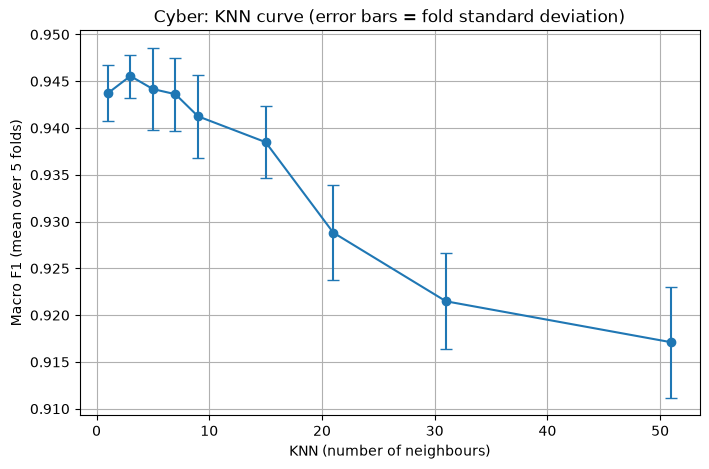

In [25]:
plt.figure(figsize=(8, 5))
plt.errorbar(KNN_GRID, knn_means, yerr=knn_stds, marker="o", capsize=4)
plt.xlabel("KNN (number of neighbours)")
plt.ylabel("Macro F1 (mean over 5 folds)")
plt.title("Cyber: KNN curve (error bars = fold standard deviation)")
plt.grid(True)
plt.show()


Macro F1 is almost flat for KNN = 1 to 7 (0.9436–0.9456): the differences between
these values are about the same size as the fold-to-fold standard deviation (0.002–0.004), so the observed differences are small relative to the descriptive fold variation. 

From KNN ≈ 9 the curve falls steadily, down to 0.917 at KNN = 51.

A larger neighbourhood averages over more distant flows, so small classes such as ransomware (208 rows)
and mitm (805 rows) are increasingly outvoted by the large classes, and macro F1, which weights every
class equally, drops. 

We choose KNN = 3, the highest mean, while noting that the observed differences among KNN = 1–7 are small; this is not an equivalence test. All KNN values remain far above the
most-frequent baseline (macro F1 ≈ 0.02).

## 6. P2.4 — Full metric set for the chosen KNN

Macro F1 (primary), weighted F1, accuracy; per-class precision, recall and F1 beside their support and confusion matrix with the semantic class names.

In [26]:

#using the chosen KNN we'll calculate the metrics for the model

best_knn = Pipeline([
    ("prep", make_cyber_preprocessor()),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
])

scores = cross_validate(best_knn, X, y, cv=folds,
                        scoring=["f1_macro", "f1_weighted", "accuracy"])

print("Macro F1    per fold:", scores["test_f1_macro"].round(4), " mean:", scores["test_f1_macro"].mean().round(4))
print("Weighted F1 per fold:", scores["test_f1_weighted"].round(4), " mean:", scores["test_f1_weighted"].mean().round(4))
print("Accuracy    per fold:", scores["test_accuracy"].round(4), " mean:", scores["test_accuracy"].mean().round(4))
print("Fit time per fold (seconds):", scores["fit_time"].round(3))

Macro F1    per fold: [0.9436 0.9473 0.949  0.9428 0.9451]  mean: 0.9456
Weighted F1 per fold: [0.9619 0.9637 0.9645 0.9592 0.9624]  mean: 0.9623
Accuracy    per fold: [0.9616 0.9632 0.9645 0.9591 0.9619]  mean: 0.9621
Fit time per fold (seconds): [0.029 0.032 0.044 0.033 0.036]


In [27]:
from sklearn.model_selection import cross_val_predict

#here we report every metric for each class

y_pred = cross_val_predict(best_knn, X, y, cv=folds)

class_names = [CLASS_NAMES[i] for i in range(10)]
print(classification_report(y, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

    backdoor      0.989     0.994     0.991      1573
        ddos      0.968     0.967     0.968      4800
         dos      0.956     0.947     0.952      4800
   injection      0.962     0.958     0.960      4800
        mitm      0.721     0.795     0.756       805
      normal      0.984     0.976     0.980      4800
    password      0.992     0.980     0.986      4800
  ransomware      0.951     0.942     0.947       208
    scanning      0.958     0.958     0.958      3542
         xss      0.949     0.966     0.958      4800

    accuracy                          0.962     34928
   macro avg      0.943     0.948     0.946     34928
weighted avg      0.963     0.962     0.962     34928



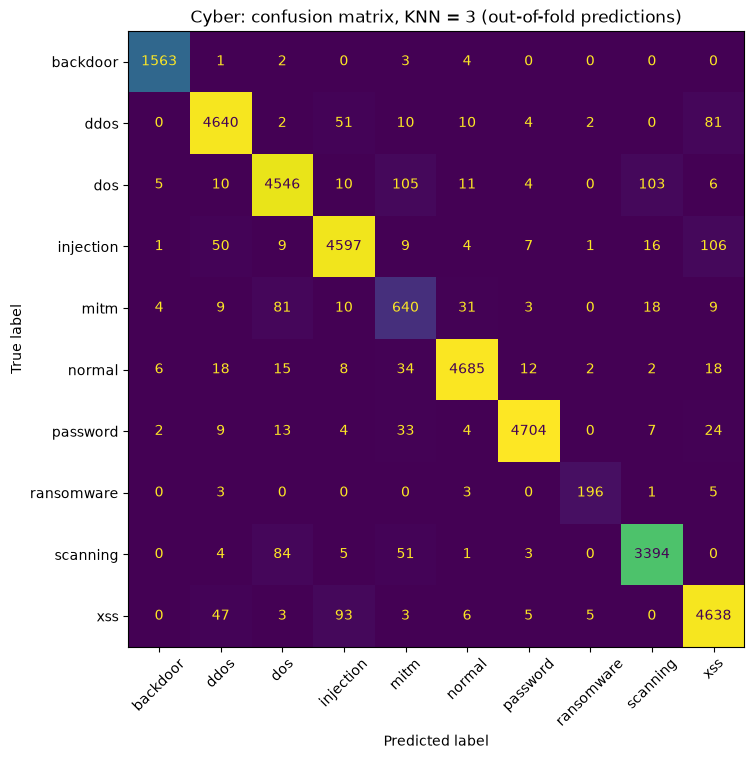

In [28]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=class_names,
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Cyber: confusion matrix, KNN = 3 (out-of-fold predictions)")
plt.show()

 With KNN = 3, macro F1 is 0.9456 (fold range 0.943–0.949), weighted F1 0.962 and
accuracy 0.962. Weighted F1 is higher than macro F1 because the large classes are classified very well,
while the weakest class, mitm (F1 0.756, support 805), counts for little in a weighted average but
for a full tenth of the macro average.

The confusion matrix shows injection / xss errors (106 and 93 respectively),
dos predicted as mitm (105) or scanning (103), mitm predicted as dos (81), and
ddos / xss errors (81 and 47 respectively). These observed confusions indicate
limits of separation using the selected flow-level predictors. Similar flow
behaviour and unobserved payload differences are possible explanations, but the
matrix does not establish the cause of a confusion. The payload itself is not
among the eleven distributed predictors. Mitm has the lowest reported F1.

Ransomware reaches F1 0.947, but with a support of only 208 each error moves
its recall by about 0.5 points, so its per-class figures are much less stable than those of the
large classes.

## 7. P2.5 — Ransomware one-vs-rest: ROC, AUC and Brier

Out-of-fold predict_proba: always report ransomware figures beside its support (208).

In [29]:
#Ransomware vs the rest (one-vs-rest): out-of-fold probability of ransomware for every flow,
#and how well it separates the real ransomware (AUC, Brier)
proba = cross_val_predict(best_knn, X, y, cv=folds, method="predict_proba")

p_ransom = proba[:, 7]      #column 7 is the probability of ransomware
is_ransom = (y == 7)        #true if the row really is ransomware


print("Ransomware support:", is_ransom.sum())
print("Distinct values of p(ransomware):", np.unique(p_ransom).round(3).tolist())
print("AUC  :", round(roc_auc_score(is_ransom, p_ransom), 4))
print("Brier:", round(brier_score_loss(is_ransom, p_ransom), 5))

Ransomware support: 208
Distinct values of p(ransomware): [0.0, 0.333, 0.667, 1.0]
AUC  : 0.9783
Brier: 0.00058


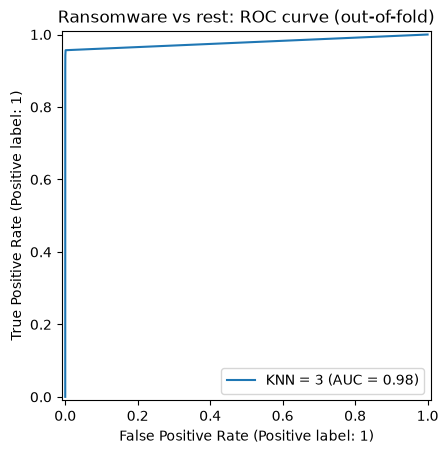

In [30]:
RocCurveDisplay.from_predictions(is_ransom, p_ransom, name="KNN = 3")
plt.title("Ransomware vs rest: ROC curve (out-of-fold)")
plt.show()

Ransomware (support 208) is separated very well from the rest: AUC = 0.978,
Brier = 0.00058 (about ten times lower than the 0.006 of a model that always says p = 0).
With KNN = 3, p(ransomware) only takes four values (0, 1/3, 2/3, 1), so the ROC curve has just
four points and is very coarse.

The rare-class prevalence also makes a constant zero-probability predictor achieve a small Brier score. The Brier value alone does not establish calibration.

## 8. P2.5 — Course-fixed rare-class decision rule

For a fixed τ: if p(ransomware) ≥ τ predict ransomware, otherwise predict the highest-probability class among the other nine. Thresholds: τ ∈ {0.05, 0.10, 0.20, 0.35, 0.50}, plus the ordinary ten-class argmax as a separate baseline row. No threshold search.

In [31]:
TAUS = [0.05, 0.10, 0.20, 0.35, 0.50]
y_true = y.to_numpy()
#here we'll predict ransomware if p(ransomware) >= tau, otherwise the best of the other nine classes
#we only evaluate the five given taus (plus the normal argmax), no threshold is chosen

#normal prediction: the class with the highest probability (out of 10)
argmax_pred = proba.argmax(axis=1)

#best class among the other nine: hide ransomware (column 7) and take the max again
proba_others = proba.copy()
proba_others[:, 7] = -1
best_other = proba_others.argmax(axis=1)


def ransomware_row(name, pred):
    tp = ((pred == 7) & (y_true == 7)).sum()          #real ransomware caught
    false_alarms = ((pred == 7) & (y_true != 7)).sum() #said ransomware but it was not
    return {
        "rule": name,
        "recall": round(tp / 208, 3),
        "precision": round(tp / (tp + false_alarms), 3),
        "caught (of 208)": tp,
        "false alarms": false_alarms,
        "other predictions changed": (pred != argmax_pred).sum(),
        "macro F1": round(f1_score(y_true, pred, average="macro"), 4),
    }


rows = [ransomware_row("10-class argmax (baseline)", argmax_pred)]
for tau in TAUS:
    pred = np.where(p_ransom >= tau, 7, best_other)
    rows.append(ransomware_row("tau = " + str(tau), pred))

pd.DataFrame(rows)

,rule,recall,precision,caught (of 208),false alarms,other predictions changed,macro F1
0,10-class argmax (baseline),0.942,0.951,196,10,0,0.9455
1,tau = 0.05,0.957,0.847,199,36,29,0.9407
2,tau = 0.1,0.957,0.847,199,36,29,0.9407
3,tau = 0.2,0.957,0.847,199,36,29,0.9407
4,tau = 0.35,0.942,0.951,196,10,0,0.9455
5,tau = 0.5,0.942,0.951,196,10,0,0.9455


Because KNN = 3 gives only four probability values, the five thresholds collapse
into two distinct rules:
- τ = 0.05, 0.10, 0.20 all mean "predict ransomware if at least 1 of the 3 neighbours is ransomware"
  (p ≥ 1/3);
- τ = 0.35, 0.50 mean "at least 2 of 3" (p ≥ 2/3), which coincides with the ten-class argmax on these observed predictions. This does not make the two decision rules identical in general; three neighbours can still produce a multiclass 1-1-1 tie.

Operational argument for lowering τ. Going from argmax to τ ≤ 1/3 catches 3 more ransomware flows
(196 → 199 of 208; recall 0.942 → 0.957). A missed ransomware flow can mean encrypted systems, so an
operator may value every extra detection highly.

What it costs. In this execution, false alarms rise from 10 to 36: 26 additional
alarms for 3 additional ransomware detections, or about 9 extra reviews per extra
detection. Precision falls from 0.951 to 0.847. The other nine classes also pay:
26 additional non-ransomware flows are labelled ransomware. Overall pooled
out-of-fold macro F1 falls from 0.9455 to 0.9407. These values describe the output
table above; they are not a forecast of live operational performance.

This is a fixed probability-and-decision exercise: no threshold is selected here, and none is carried into
model selection. The project's primary metric remains macro F1 with ordinary argmax prediction.

## 9. P2.6 — Dry-run submission file (cyber)

Build entregas_prueba/cyber_dry_run.csv (row_id,attack_code) from a development subset, and save that subset's features so R5 can run validate_submission.py.

In [32]:
train_idx = folds[0][0]
val_idx = folds[0][1]

#train KNN = 3 on the training part of fold 0
best_knn.fit(X.iloc[train_idx], y.iloc[train_idx])

#the validation part of fold 0 plays the role of the "final test"
subset = dev.iloc[val_idx]

#file 1: the features of the subset (row_id + the 11 features, NO target)
subset[["row_id"] + FEATURES].to_csv("../entregas_prueba/cyber_dry_run_features.csv", index=False)

#file 2: our predictions in the exact submission format
submission = pd.DataFrame({
    "row_id": subset["row_id"],
    "attack_code": best_knn.predict(subset[FEATURES]),
})
submission.to_csv("../entregas_prueba/cyber_dry_run.csv", index=False)

print(submission.shape)
submission.head()

(6986, 2)


,row_id,attack_code
1,C00001,9
4,C00004,1
17,C00017,5
20,C00020,2
22,C00022,6


In [33]:
#we validate the submission
!python ../herramientas/validate_submission.py cyber ../entregas_prueba/cyber_dry_run.csv ../entregas_prueba/cyber_dry_run_features.csv ../datos/cyber/cyber_class_codes.json

valid


# P2.6 — The OneR interpretation question

OneR builds a prediction rule from one selected input attribute. With mixed nominal and continuous predictors, the rule is not fully specified until the representation and rule-building choices are fixed. Continuous predictors require a discretisation policy: the number of intervals and their boundaries determine which numeric values share a rule. Category handling must define what happens for an unseen or missing value. The implementation also needs tie-breaking for equally frequent classes or equally good attributes, and a policy for categories or intervals with very little support. These choices determine the complexity and behaviour of the baseline. Any data-dependent boundaries, rules and attribute selection must be learned on the training portion of each fold. Consequently, a generic OneR baseline cannot be inserted without these additional design decisions. The required baseline here is `DummyClassifier(strategy="most_frequent")`; no custom OneR estimator is implemented.

## Data references

The eight TON_IoT references required by the course provenance record are:

1. Moustafa, Nour."A new distributed architecture for evaluating AI-based security systems
   at the edge: Network TON_IoT datasets." *Sustainable Cities and Society* (2021): 102994.
2. Booij, Tim M., Irina Chiscop, Erik Meeuwissen, Nour Moustafa, and Frank T. H. den Hartog.
   "ToN IoT — The role of heterogeneity and the need for standardization of features and
   attack types in IoT network intrusion datasets." *IEEE Internet of Things Journal* (2021).
3. Alsaedi, Abdullah, Nour Moustafa, Zahir Tari, Abdun Mahmood, and Adnan Anwar. "TON_IoT
   telemetry dataset: a new generation dataset of IoT and IIoT for data-driven Intrusion
   Detection Systems." *IEEE Access* 8 (2020): 165130–165150.
4. Moustafa, Nour, M. Keshk, E. Debie and H. Janicke. "Federated TON_IoT Windows Datasets for
   Evaluating AI-Based Security Applications." *2020 IEEE 19th International Conference on
   Trust, Security and Privacy in Computing and Communications (TrustCom)*, 2020,
   pp. 848–855, doi: 10.1109/TrustCom50675.2020.00114.
5. Moustafa, Nour, M. Ahmed and S. Ahmed. "Data Analytics-Enabled Intrusion Detection:
   Evaluations of ToN_IoT Linux Datasets." *2020 IEEE 19th International Conference on Trust,
   Security and Privacy in Computing and Communications (TrustCom)*, 2020, pp. 727–735,
   doi: 10.1109/TrustCom50675.2020.00100.
6. Moustafa, Nour. "New Generations of Internet of Things Datasets for Cybersecurity
   Applications based Machine Learning: TON_IoT Datasets." *Proceedings of the eResearch
   Australasia Conference, Brisbane, Australia*. 2019.
7. Moustafa, Nour. "A systemic IoT-Fog-Cloud architecture for big-data analytics and cyber
   security systems: a review of fog computing." *arXiv preprint* arXiv:1906.01055 (2019).
8. Ashraf, Javed, Marwa Keshk, Nour Moustafa, Mohamed Abdel-Basset, Hasnat Khurshid,
   Asim D. Bakhshi, and Reham R. Mostafa. "IoTBoT-IDS: A Novel Statistical Learning-enabled
   Botnet Detection Framework for Protecting Networks of Smart Cities." *Sustainable Cities
   and Society* (2021): 103041.